# Stable Diffusion 실습

원본에 저장된 버전인 `diffusers==0.33.1`, `transformers==4.52.4`를 기준으로 설치 순서를 정리했습니다.
`is_flax_available` 오류는 서로 다른 버전의 Diffusers 코드가 메모리 또는 설치 경로에 섞인 경우 발생할 수 있습니다.

## 실행 순서

1. Colab에서 **런타임 → 런타임 유형 변경**으로 GPU를 선택합니다.
2. 아래 **설치 셀만** 실행하고 설치가 성공했는지 확인합니다.
3. **런타임 → 세션 다시 시작**(영문: Restart session)을 선택합니다.
4. 설치 셀을 건너뛰고 **설치 확인 셀부터** 순서대로 실행합니다.

처음에는 '모두 실행'을 사용하지 마세요. 설치 후에는 이미 불러온 모듈을 비우기 위해 세션을 다시 시작해야 합니다.
Colab의 기존 PyTorch/CUDA 설치를 사용합니다. 이미지 생성과 인페인팅 코드는 원본을 유지했으며, 이전 실행 결과는 지웠습니다.
이 파일은 구조와 코드 문법을 확인한 수정본이며, 실제 Colab GPU에서 이미지 생성까지 실행한 결과는 아닙니다.

근거: [Diffusers 0.33.1 내부 함수 내보내기](https://github.com/huggingface/diffusers/blob/v0.33.1/src/diffusers/utils/__init__.py),
[Transformers 4.52.4 의존성](https://github.com/huggingface/transformers/blob/v4.52.4/setup.py).


In [1]:
# 1. 설치 셀: 한 번 실행한 뒤 반드시 세션을 다시 시작하세요.
# 현재 노트북의 Python에 설치하며, 설치가 실패하면 즉시 중단합니다.
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "uninstall", "-y", "diffusers"
])
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--no-cache-dir",
    "diffusers==0.33.1",
    "transformers==4.52.4",
    "huggingface-hub>=0.30.0,<1.0",
    "accelerate",
    "safetensors",
])

_sd_restart_required = True
print("설치 완료: 런타임 → 세션 다시 시작 후, 아래 설치 확인 셀부터 실행하세요.")


설치 완료: 런타임 → 세션 다시 시작 후, 아래 설치 확인 셀부터 실행하세요.


## 세션 다시 시작 후 아래 셀부터 실행
설치 셀을 다시 실행하면 재시작이 다시 필요합니다.


In [4]:
# 2. 설치 확인 셀: 세션을 다시 시작한 뒤 여기서부터 실행하세요.
if globals().get("_sd_restart_required", False):
    raise RuntimeError(
        "설치가 완료되었습니다. 런타임 → 세션 다시 시작 후 "
        "설치 셀을 건너뛰고 이 셀부터 실행하세요."
    )

import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])
for package in ["diffusers", "transformers", "huggingface-hub", "torch"]:
    print(f"{package}: {version(package)}")

import diffusers
import transformers
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline

print("diffusers 경로:", diffusers.__file__)
print("Stable Diffusion 파이프라인 import 성공")


Python: 3.13.15
diffusers: 0.33.1
transformers: 4.52.4
huggingface-hub: 0.36.2
torch: 2.11.0+cu130
diffusers 경로: /usr/local/lib/python3.13/dist-packages/diffusers/__init__.py
Stable Diffusion 파이프라인 import 성공


In [5]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [6]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

safety_checker/model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

...

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


  0%|          | 0/30 [00:00<?, ?it/s]

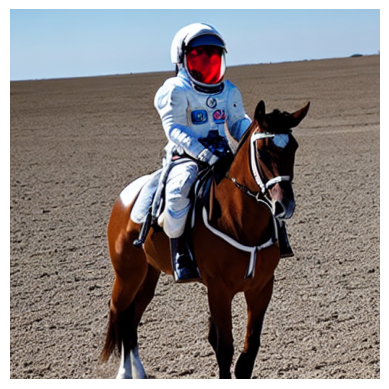

Image saved as generated_defect_0.png


In [7]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "runwayml/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(42)

with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        # generator=generator
    ).images

# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.


Using device: cuda


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, du

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

safety_checker/model.fp16.safetensors:   0%|          | 0.00/608M [00:00<?, ?B/s]

unet/diffusion_pytorch_model.fp16.safete(…):   0%|          | 0.00/1.72G [00:00<?, ?B/s]

text_encoder/model.fp16.safetensors:   0%|          | 0.00/246M [00:00<?, ?B/s]

vae/diffusion_pytorch_model.fp16.safeten(…):   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Inpainting pipeline loaded.


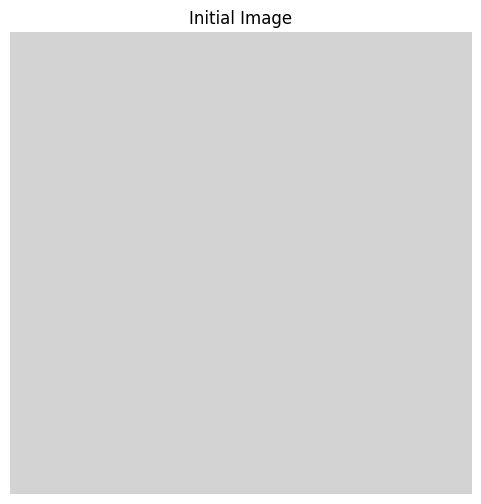

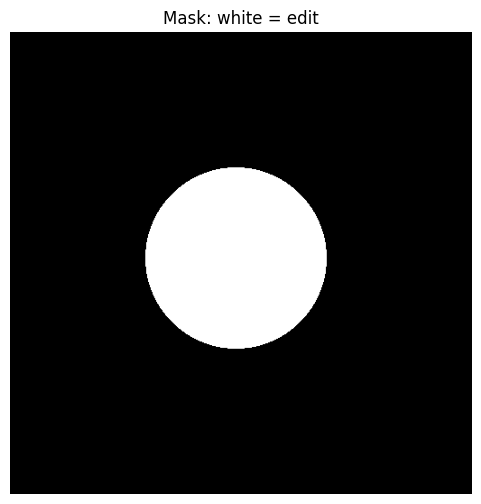

  0%|          | 0/50 [00:00<?, ?it/s]

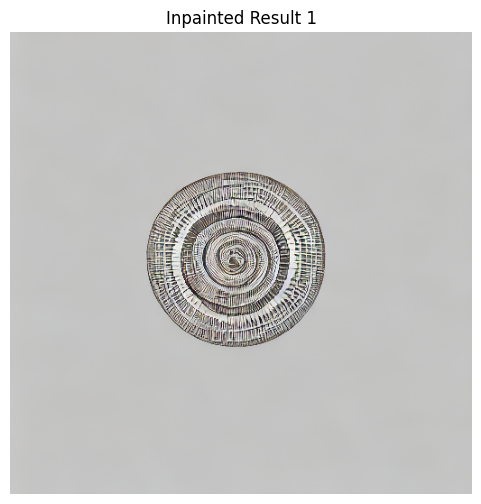

Saved: inpainted_defect_0.png


In [ ]:
import gc
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# 이전 모델이 GPU 메모리를 중복 사용하지 않도록 정리합니다.
for pipeline_name in ("pipe_text2img", "pipe_inpaint"):
    old_pipeline = globals().get(pipeline_name)
    if old_pipeline is not None:
        old_pipeline.to("cpu")
globals().pop("pipe_inpaint", None)
old_pipeline = None
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

def display_image(image, title="Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap="gray" if image.mode == "L" else None)
    plt.title(title)
    plt.axis("off")
    plt.show()
    plt.close()

# FP16 파일을 명시해서 모델을 불러옵니다.
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting"
pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    model_id_inpaint,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    variant="fp16", # 기존 코드와 다르게 해당 옵션을 추가하여 FP16 모델을 명시적으로 불러옵니다.
    use_safetensors=True,
).to(device)
print("Inpainting pipeline loaded.")

# 회색 이미지와 중앙 원형 마스크를 만듭니다.
init_image = Image.new("RGB", (512, 512), "lightgray")
mask_image = Image.new("L", (512, 512), 0)
draw = ImageDraw.Draw(mask_image)
draw.ellipse((150, 150, 350, 350), fill=255)

display_image(init_image, "Initial Image")
display_image(mask_image, "Mask: white = edit")

prompt_inpaint_defect = "A deep circular dent with rough edges"
negative_prompt_inpaint = "smooth, perfect, flat, no dent, blurry"
generator = torch.Generator(device=device).manual_seed(42)

with torch.inference_mode():
    inpainted_images = pipe_inpaint(
        prompt=prompt_inpaint_defect,
        image=init_image,
        mask_image=mask_image,
        negative_prompt=negative_prompt_inpaint,
        num_inference_steps=50,
        guidance_scale=7.5,
        generator=generator,
    ).images

for i, image in enumerate(inpainted_images):
    display_image(image, f"Inpainted Result {i + 1}")
    image.save(f"inpainted_defect_{i}.png")
    print(f"Saved: inpainted_defect_{i}.png")

Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, du

Using device: cuda


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, du

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Inpainting pipeline loaded.


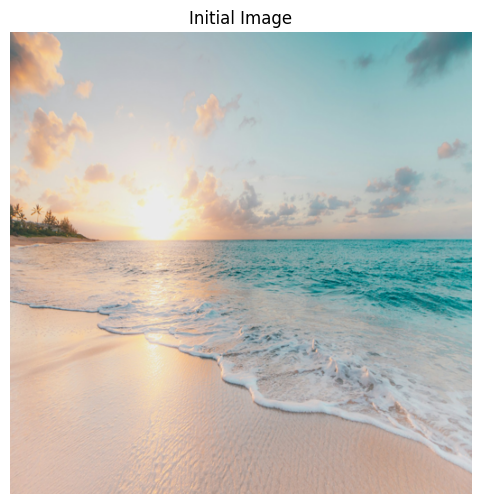

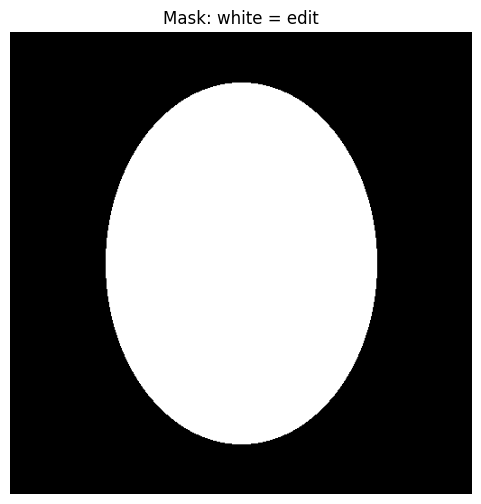

  0%|          | 0/50 [00:00<?, ?it/s]

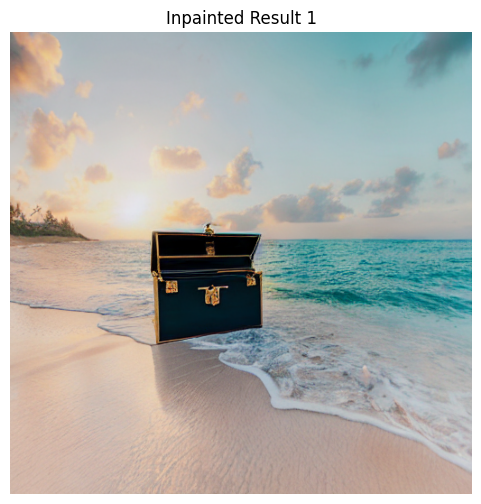

Saved: result_inpainted_0.png


In [11]:
import gc
from io import BytesIO
import requests
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# 이전 모델이 GPU 메모리를 중복 사용하지 않도록 정리합니다.
for pipeline_name in ("pipe_text2img", "pipe_inpaint"):
    old_pipeline = globals().get(pipeline_name)
    if old_pipeline is not None:
        old_pipeline.to("cpu")
globals().pop("pipe_inpaint", None)
old_pipeline = None
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

def display_image(image, title="Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap="gray" if image.mode == "L" else None)
    plt.title(title)
    plt.axis("off")
    plt.show()
    plt.close()

# FP16 파일을 명시해서 모델을 불러옵니다.
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting"
pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    model_id_inpaint,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    variant="fp16",
    use_safetensors=True,
).to(device)
print("Inpainting pipeline loaded.")

# 해변 이미지를 불러옵니다.
image_url = (
    "https://images.unsplash.com/photo-1507525428034-b723cf961d3e"
    "?q=80&w=2070&auto=format&fit=crop"
)
try:
    response = requests.get(image_url, timeout=30)
    response.raise_for_status()
    init_image = Image.open(BytesIO(response.content)).convert("RGB")
    init_image = init_image.resize((512, 512))
except Exception as e:
    print(f"Image load failed: {e}. Using placeholder image.")
    init_image = Image.new("RGB", (512, 512))
    draw = ImageDraw.Draw(init_image)
    draw.rectangle((0, 0, 512, 280), fill="skyblue")
    draw.rectangle((0, 280, 512, 512), fill="goldenrod")
    draw.ellipse((400, 60, 440, 100), fill="gold")

# 흰색 타원 영역을 수정합니다.
mask_image = Image.new("L", (512, 512), 0)
draw = ImageDraw.Draw(mask_image)
draw.ellipse((106, 56, 406, 456), fill=255)

display_image(init_image, "Initial Image")
display_image(mask_image, "Mask: white = edit")

prompt = "A treasure chest buried in the sand"
negative_prompt = (
    "blurry, deformed, cartoon, illustration, watermark, text, "
    "signature, extra limbs"
)
generator = torch.Generator(device=device).manual_seed(1234)

with torch.inference_mode():
    result = pipe_inpaint(
        prompt=prompt,
        image=init_image,
        mask_image=mask_image,
        negative_prompt=negative_prompt,
        guidance_scale=8.5,
        num_inference_steps=50,
        generator=generator,
    )

for i, out_img in enumerate(result.images):
    display_image(out_img, f"Inpainted Result {i + 1}")
    out_img.save(f"result_inpainted_{i}.png")
    print(f"Saved: result_inpainted_{i}.png")